# NLP basics and text vectorisation: restaurant reviews

**Week 4 · NLP, Transformers & LLMs · Notebook 1 of 2**

Computers can't read words, only numbers. This notebook follows one question all the way through: **how do we turn a restaurant review into numbers a model can use?**

| Part | Topic |
|---|---|
| 1 | The data |
| 2 | NLP basics: tokenisation, normalisation, stop words, stemming vs lemmatisation, n-grams |
| 3 | Counting words: Bag of Words and TF-IDF (and a first classifier) |
| 4 | Word embeddings: Word2Vec (CBOW and skip-gram) and GloVe |
| 5 | Vectors vs embeddings, with model examples |
| 6 | Context matters: attention, transformers and BERT |
| 7 | Sentence embeddings and semantic search (the "R" in RAG) |
| 8 | From embeddings to LLMs: how LLMs are trained, in brief |

> **Setup:** `uv add pandas numpy scikit-learn matplotlib nltk gensim sentence-transformers transformers torch jupyter`
> The first run downloads a few small models (GloVe 66 MB, MiniLM 90 MB, BERT 440 MB).

In [1]:
import re
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.precision", 3)
SEED = 42

## 1. The data

1,000 short restaurant reviews, each labelled **Liked = 1** (positive) or **0** (negative).

In [2]:
URL = ("https://raw.githubusercontent.com/PacktPublishing/40-Algorithms-Every-Programmer-Should-Know/"
       "master/Chapter09/Restaurant_Reviews.tsv")
df = pd.read_csv(URL, sep="\t", quoting=3)        # quoting=3: treat quote marks as ordinary characters

print(df.shape)
print(df["Liked"].value_counts())
df.sample(8, random_state=SEED)

(1000, 2)
Liked
1    500
0    500
Name: count, dtype: int64


,Review,Liked
521,If you haven't gone here GO NOW!,1
737,"Try them in the airport to experience some tasty food and speedy, friendly s...",1
740,The restaurant is very clean and has a family restaurant feel to it.,1
660,"I personally love the hummus, pita, baklava, falafels and Baba Ganoush (it's...",1
411,"Come hungry, leave happy and stuffed!",1
678,It's a great place and I highly recommend it.,1
626,Best of luck to the rude and non-customer service focused new management.,0
513,Reasonably priced also!,1


In [3]:
df["n_words"] = df["Review"].str.split().str.len()
df["n_words"].describe()

count    1000.000
mean       10.894
std         6.257
min         1.000
25%         6.000
50%        10.000
75%        15.000
max        32.000
Name: n_words, dtype: float64

The reviews are **short** (about 11 words on average) and the classes are **balanced** (500 / 500), so accuracy is a fair metric here, unlike the imbalanced problems in Week 1.

---
## 2. NLP basics: cleaning and splitting text

### 2.1 Tokenisation: splitting text into pieces

A **token** is a unit of text: usually a word, sometimes punctuation or part of a word.

In [4]:
import nltk
for pkg in ["punkt_tab", "stopwords", "wordnet", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)

from nltk.tokenize import word_tokenize

review = "Wow... Loved this place! The wasn't-so-great service didn't ruin it :)"
print("str.split():    ", review.split())
print("word_tokenize():", word_tokenize(review))

str.split():     ['Wow...', 'Loved', 'this', 'place!', 'The', "wasn't-so-great", 'service', "didn't", 'ruin', 'it', ':)']
word_tokenize(): ['Wow', '...', 'Loved', 'this', 'place', '!', 'The', "wasn't-so-great", 'service', 'did', "n't", 'ruin', 'it', ':', ')']


- `str.split()` only splits on spaces, so punctuation stays glued to words (`place!`).
- `word_tokenize` separates punctuation and splits contractions (`did` + `n't`), which matters a lot for sentiment.
- Modern LLMs use **subword tokens** (e.g. `unbelievable` → `un`, `believ`, `able`), so they can handle any word. We'll see that with BERT in Part 6.

### 2.2 Normalisation

Make different spellings of the same thing look the same: lower-case, remove URLs and numbers, strip extra punctuation.

In [5]:
def normalise(text: str) -> str:
    text = text.lower()
    text = re.sub(r"http\S+", " ", text)            # URLs
    text = re.sub(r"[^a-z'\s]", " ", text)          # keep letters and apostrophes
    return re.sub(r"\s+", " ", text).strip()

normalise("The FOOD was AMAZING!!! 10/10, see http://example.com")

'the food was amazing see'

### 2.3 Stop words, and a trap

**Stop words** are very common words (`the`, `is`, `and`) that carry little meaning on their own, so they're often removed. But look at what NLTK's standard list contains:

In [6]:
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))
print(len(STOP), "stop words")
print("Includes:", sorted(w for w in STOP if w in {"not", "no", "nor"}),
      "and", sum(w.endswith("n't") for w in STOP), "contractions like", ["don't", "wasn't", "isn't"])

198 stop words
Includes: ['no', 'nor', 'not'] and 18 contractions like ["don't", "wasn't", "isn't"]


⚠️ **"not", "no" and "don't" are on the list.** Removing them turns *"the food was **not** good"* into *"food good"*, which flips the sentiment! For sentiment analysis, keep the negations.

One more catch: `word_tokenize` splits "wasn't" into `was` + `n't`, so a stop list containing "wasn't" never matches. We map `n't` → `not` so every negation looks the same.

In [7]:
NEGATIONS = {"not", "no", "nor"} | {w for w in STOP if w.endswith("n't")}
STOP_KEEP_NEG = STOP - NEGATIONS

def tokenise(text: str) -> list[str]:
    return ["not" if t == "n't" else t for t in word_tokenize(text)]   # wasn't → was + not

text = "the food was not good and the service wasn't great"
tokens = tokenise(text)
print("Remove all stop words: ", [t for t in tokens if t not in STOP])
print("Keep negations:        ", [t for t in tokens if t not in STOP_KEEP_NEG])

Remove all stop words:  ['food', 'good', 'service', 'great']
Keep negations:         ['food', 'not', 'good', 'service', 'not', 'great']


### 2.4 Stemming vs lemmatisation

Both reduce a word to a base form, so "loved", "loving" and "loves" count as the same word.

| | Stemming | Lemmatisation |
|---|---|---|
| How | Chops off endings with rules | Looks the word up in a dictionary, using its part of speech |
| Result | Can be a non-word (`studi`) | Always a real word (`study`) |
| Speed | Very fast | Slower |

In [8]:
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

stemmer, lemmatizer = PorterStemmer(), WordNetLemmatizer()

def wordnet_pos(tag: str):
    return {"J": wordnet.ADJ, "V": wordnet.VERB, "R": wordnet.ADV}.get(tag[0], wordnet.NOUN)

words = ["loved", "loving", "studies", "better", "dishes", "was", "tasting", "friendlier"]
tags = nltk.pos_tag(words)
pd.DataFrame({
    "word": words,
    "stem (Porter)": [stemmer.stem(w) for w in words],
    "lemma (no POS)": [lemmatizer.lemmatize(w) for w in words],
    "lemma (with POS)": [lemmatizer.lemmatize(w, wordnet_pos(t)) for w, t in tags],
})

,word,stem (Porter),lemma (no POS),lemma (with POS)
0,loved,love,loved,love
1,loving,love,loving,loving
2,studies,studi,study,study
3,better,better,better,well
4,dishes,dish,dish,dish
5,was,wa,wa,be
6,tasting,tast,tasting,taste
7,friendlier,friendlier,friendlier,friendlier


Without the part of speech, the lemmatiser assumes every word is a noun, so `loved` stays `loved` and `was` becomes the odd `wa`. With POS tags, `loved` → `love`, `tasting` → `taste` and `was` → `be`.

POS tagging is a guess, and it's least reliable on single words: here `better` was tagged as an adverb, so it became `well` (as an adjective it would be `good`). Inside real sentences the tagger has context and does better, which is why we tag whole reviews.

### 2.5 Putting it together: a cleaning pipeline

In [9]:
def clean(text: str, keep_negations: bool = True, lemmatise: bool = True) -> str:
    tokens = tokenise(normalise(text))
    stop = STOP_KEEP_NEG if keep_negations else STOP
    tokens = [t for t in tokens if t not in stop and len(t) > 1]
    if lemmatise:
        tokens = [lemmatizer.lemmatize(t, wordnet_pos(tag)) for t, tag in nltk.pos_tag(tokens)]
    return " ".join(tokens)

df["clean"] = df["Review"].apply(clean)
df[["Review", "clean", "Liked"]].head(8)

,Review,clean,Liked
0,Wow... Loved this place.,wow love place,1
1,Crust is not good.,crust not good,0
2,Not tasty and the texture was just nasty.,not tasty texture nasty,0
3,Stopped by during the late May bank holiday off Rick Steve recommendation an...,stop late may bank holiday rick steve recommendation love,1
4,The selection on the menu was great and so were the prices.,selection menu great price,1
5,Now I am getting angry and I want my damn pho.,get angry want damn pho,0
6,Honeslty it didn't taste THAT fresh.),honeslty not taste fresh,0
7,The potatoes were like rubber and you could tell they had been made up ahead...,potato like rubber could tell make ahead time keep warmer,0


### 2.6 n-grams

An **n-gram** is a run of *n* tokens in a row. Single words (unigrams) lose word order; **bigrams** keep a little of it, e.g. `not good`.

In [10]:
from nltk.util import ngrams
tokens = df.loc[1, "clean"].split()
print("tokens: ", tokens)
print("bigrams:", list(ngrams(tokens, 2)))

tokens:  ['crust', 'not', 'good']
bigrams: [('crust', 'not'), ('not', 'good')]


---
## 3. Counting words: Bag of Words and TF-IDF

### 3.1 Bag of Words (BoW)

Build a **vocabulary** of every word, then represent each review as a list of **counts**, one per vocabulary word. Word order is thrown away ("a bag" of words).

In [11]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

mini = ["the food was good", "the food was not good", "good service good food"]
bow = CountVectorizer()
X_mini = bow.fit_transform(mini)
pd.DataFrame(X_mini.toarray(), columns=bow.get_feature_names_out(), index=mini)

,food,good,not,service,the,was
the food was good,1,1,0,0,1,1
the food was not good,1,1,1,0,1,1
good service good food,1,2,0,1,0,0


Notice that *"the food was good"* and *"the food was not good"* differ by a single column, even though they mean opposite things. Adding **bigrams** helps:

In [12]:
bow2 = CountVectorizer(ngram_range=(1, 2))
pd.DataFrame(bow2.fit_transform(mini).toarray(), columns=bow2.get_feature_names_out(), index=mini)

,food,food was,good,good food,good service,not,not good,service,service good,the,the food,was,was good,was not
the food was good,1,1,1,0,0,0,0,0,0,1,1,1,1,0
the food was not good,1,1,1,0,0,1,1,0,0,1,1,1,0,1
good service good food,1,0,2,1,1,0,0,1,1,0,0,0,0,0


In [13]:
bow_full = CountVectorizer()
X_bow = bow_full.fit_transform(df["clean"])
print("Matrix shape:", X_bow.shape, "(reviews × vocabulary words)")
print(f"Non-zero values: {X_bow.nnz} of {X_bow.shape[0] * X_bow.shape[1]:,} ({X_bow.nnz / (X_bow.shape[0] * X_bow.shape[1]):.2%})")

Matrix shape: (1000, 1662) (reviews × vocabulary words)
Non-zero values: 5654 of 1,662,000 (0.34%)


Each review uses only a handful of the ~1,700 vocabulary words, so the matrix is almost all zeros: a **sparse** vector. scikit-learn stores only the non-zero entries.

### 3.2 TF-IDF: weighting words by how informative they are

**TF-IDF = term frequency × inverse document frequency**
- **TF**: how often the word appears *in this review*
- **IDF** = log(number of reviews ÷ number of reviews containing the word): **rare words score higher**, words that appear everywhere ("food", "place") score lower

In [14]:
tfidf = TfidfVectorizer()
X_tfidf = tfidf.fit_transform(df["clean"])

idf = pd.Series(tfidf.idf_, index=tfidf.get_feature_names_out()).sort_values()
print("Most common words (lowest IDF):", list(idf.head(8).index))
print("Rarest words (highest IDF):    ", list(idf.tail(8).index))

Most common words (lowest IDF): ['not', 'food', 'place', 'good', 'service', 'go', 'great', 'back']
Rarest words (highest IDF):     ['hook', 'honor', 'honeslty', 'holiday', 'hole', 'hold', 'hopefully', 'line']


In [15]:
i = 0
row = pd.Series(X_tfidf[i].toarray()[0], index=tfidf.get_feature_names_out())
print("Review:", df.loc[i, "Review"])
row[row > 0].sort_values(ascending=False)

Review: Wow... Loved this place.


wow      0.764
love     0.524
place    0.377
dtype: float64

### 3.3 A first sentiment classifier

Same model (logistic regression), same 5-fold cross-validation; only the text representation changes.

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
y = df["Liked"].values
df["clean_no_neg"] = df["Review"].apply(lambda t: clean(t, keep_negations=False))

def cv_accuracy(pipe, text_col):
    scores = cross_val_score(pipe, df[text_col], y, cv=cv, scoring="accuracy")
    return round(scores.mean(), 3), round(scores.std(), 3)

results = {
    "BoW (stop words incl. 'not' removed)": cv_accuracy(make_pipeline(CountVectorizer(), LogisticRegression(max_iter=1000)), "clean_no_neg"),
    "BoW (negations kept)":                 cv_accuracy(make_pipeline(CountVectorizer(), LogisticRegression(max_iter=1000)), "clean"),
    "BoW + bigrams":                        cv_accuracy(make_pipeline(CountVectorizer(ngram_range=(1, 2)), LogisticRegression(max_iter=1000)), "clean"),
    "TF-IDF":                               cv_accuracy(make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000)), "clean"),
    "TF-IDF + bigrams":                     cv_accuracy(make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), LogisticRegression(max_iter=1000)), "clean"),
}
comparison = pd.DataFrame(results, index=["accuracy", "± std"]).T
comparison

,accuracy,± std
BoW (stop words incl. 'not' removed),0.786,0.014
BoW (negations kept),0.815,0.024
BoW + bigrams,0.818,0.024
TF-IDF,0.821,0.020
TF-IDF + bigrams,0.829,0.015


Keeping negations helps, which is the stop-word trap from section 2.3 showing up in the results. Differences of about 0.01–0.02 are within the ± std, so don't over-read small gaps.

**Which words drive the predictions?** Logistic regression has one weight per word:

In [17]:
pipe = make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000)).fit(df["clean"], y)
weights = pd.Series(pipe[-1].coef_[0], index=pipe[0].get_feature_names_out()).sort_values()
print("Most negative words:", list(weights.head(10).index))
print("Most positive words:", list(weights.tail(10).index[::-1]))

Most negative words: ['not', 'bad', 'no', 'never', 'terrible', 'slow', 'minute', 'bland', 'wait', 'get']
Most positive words: ['great', 'good', 'delicious', 'love', 'friendly', 'amaze', 'fantastic', 'nice', 'awesome', 'perfect']


**Limits of counting words**
- **No meaning:** "delicious" and "tasty" are completely unrelated columns.
- **Huge and sparse:** one column per word.
- **No context:** "cold beer" (good) and "cold food" (bad) use the same `cold` column.

---
## 4. Word embeddings: words as meaningful, dense vectors

Instead of one column per word, an **embedding** represents each word as a short, **dense** list of numbers (e.g. 50 or 300), learned so that **words used in similar contexts get similar vectors**.

> *"You shall know a word by the company it keeps"* (J. R. Firth)

### 4.1 Word2Vec: CBOW vs skip-gram

Word2Vec learns embeddings with a small neural network trained on a simple guessing game:

| | CBOW (Continuous Bag of Words) | Skip-gram |
|---|---|---|
| Task | Predict the **middle word** from its neighbours | Predict the **neighbours** from the middle word |
| Example | `the ___ was delicious` → `pasta` | `pasta` → `the`, `was`, `delicious` |
| Strengths | Faster; good for frequent words | Better for rare words and small data |
| gensim | `sg=0` | `sg=1` |

In [18]:
from gensim.models import Word2Vec

sentences = [t.split() for t in df["clean"]]
cbow = Word2Vec(sentences, vector_size=50, window=3, min_count=2, sg=0, epochs=200, seed=SEED, workers=1)
skipgram = Word2Vec(sentences, vector_size=50, window=3, min_count=2, sg=1, epochs=200, seed=SEED, workers=1)

print("Vector for 'food' (first 8 of 50 numbers):", np.round(cbow.wv["food"][:8], 2))
for name, m in [("CBOW", cbow), ("Skip-gram", skipgram)]:
    print(f"{name:<10} most similar to 'great':", [w for w, _ in m.wv.most_similar("great", topn=6)])

Vector for 'food' (first 8 of 50 numbers): [-0.77 -1.01  0.62  1.37  0.33 -0.25  0.25  0.04]
CBOW       most similar to 'great': ['provide', 'hip', 'impeccable', 'perfection', 'watch', 'delish']
Skip-gram  most similar to 'great': ['provide', 'impeccable', 'guy', 'option', 'lovely', 'delish']


With only 1,000 short reviews (~10,000 words), the results are noisy. Word2Vec needs **millions** of sentences to learn good meanings. That's why we usually **reuse embeddings pretrained on huge corpora**.

### 4.2 GloVe: pretrained word vectors

**GloVe** (Global Vectors, Stanford) learns from word **co-occurrence counts** across a huge corpus. Here: 400,000 words, 50 dimensions, trained on Wikipedia and newswire text.

In [19]:
import contextlib, io
import gensim.downloader as api

with contextlib.redirect_stdout(io.StringIO()):   # hide the download progress bar
    glove = api.load("glove-wiki-gigaword-50")   # ~66 MB, downloaded once

for w in ["delicious", "rude", "pizza", "waiter"]:
    print(f"{w:<10}", [x for x, _ in glove.most_similar(w, topn=6)])

delicious  ['tasty', 'savory', 'spicy', 'dessert', 'flavorful', 'flavor']
rude       ['sarcastic', 'obnoxious', 'downright', 'polite', 'insensitive', 'disrespectful']
pizza      ['sandwich', 'sandwiches', 'snack', 'bakery', 'fries', 'burgers']
waiter     ['waitress', 'bartender', 'hairdresser', 'doorman', 'waiters', 'busboy']


In [20]:
pairs = [("delicious", "tasty"), ("delicious", "disgusting"), ("waiter", "waitress"), ("food", "laptop")]
for a, b in pairs:
    print(f"similarity({a}, {b}) = {glove.similarity(a, b):.2f}")

print("\nking - man + woman ≈", glove.most_similar(positive=["king", "woman"], negative=["man"], topn=1)[0][0])

similarity(delicious, tasty) = 0.93
similarity(delicious, disgusting) = 0.51
similarity(waiter, waitress) = 0.88
similarity(food, laptop) = 0.32

king - man + woman ≈ queen


- Related words are close together (cosine similarity near 1); unrelated ones aren't.
- ⚠️ "delicious" and "disgusting" are still fairly similar. Both appear in food contexts, and **embeddings capture "used in similar contexts", which isn't the same as "means the same thing"**. That's a real limitation for sentiment.

### 4.3 A review vector = the average of its word vectors

In [21]:
def avg_glove(text: str) -> np.ndarray:
    vecs = [glove[w] for w in text.split() if w in glove]
    return np.mean(vecs, axis=0) if vecs else np.zeros(glove.vector_size)

X_glove = np.vstack(df["clean"].apply(avg_glove))
acc = cross_val_score(LogisticRegression(max_iter=1000), X_glove, y, cv=cv)
results["GloVe average (50 dims)"] = (round(acc.mean(), 3), round(acc.std(), 3))
print("Shape:", X_glove.shape, "· accuracy", round(acc.mean(), 3))

Shape: (1000, 50) · accuracy 0.765


Only 50 dense numbers per review, and they know that "tasty" and "delicious" are related, yet it scores **lower than TF-IDF** here. Averaging blurs everything together: word order and negation are lost ("not good" ≈ "good"), and the 50-dimension GloVe vectors were trained on news and Wikipedia, not reviews. Static embeddings alone aren't a magic upgrade.

---
## 5. Vectors vs embeddings

Both are lists of numbers representing text. The difference is **how the numbers are made** and **what they capture**.

| | Count-based vectors | Embeddings |
|---|---|---|
| How they're made | **Counted** with fixed rules | **Learned** by a model |
| Size | One dimension per vocabulary word (thousands) | Fixed and small (50–4,096) |
| Values | Mostly zeros (**sparse**) | All non-zero (**dense**) |
| Meaning | None: "tasty" ≠ "delicious" | Similar meanings → similar vectors |
| Examples | One-hot, **Bag of Words**, **TF-IDF** | See below |

**Embedding model examples**

| Type | One vector per… | Examples |
|---|---|---|
| **Static word** embeddings | word (same everywhere) | **Word2Vec** (CBOW, skip-gram), **GloVe**, FastText (handles sub-words) |
| **Contextual word** embeddings | word *in this sentence* | ELMo, **BERT**, RoBERTa |
| **Sentence / document** embeddings | sentence or passage | **Sentence-Transformers** (`all-MiniLM-L6-v2`), OpenAI `text-embedding-3-small`, Cohere Embed, `nomic-embed-text` (runs locally in Ollama) |

So **every embedding is a vector, but not every vector is an embedding**.

---
## 6. Context matters: attention, transformers and BERT

Static embeddings give a word **one vector, whatever the sentence**. But "cold" is *good* in "an ice cold beer" and *bad* in "the food arrived cold".

In [22]:
print("GloVe vector for 'cold' is identical in both sentences, similarity =",
      round(float(glove.similarity("cold", "cold")), 2))

GloVe vector for 'cold' is identical in both sentences, similarity = 1.0


### Attention and the transformer, in plain words

**Attention** lets every word look at every other word in the sentence and decide how much each one matters to its meaning. In *"the food arrived **cold**"*, "cold" pays attention to "food" and "arrived"; in *"ice **cold** beer"*, to "ice" and "beer". So each word's vector is **rebuilt using its context**.

A **transformer** stacks many attention layers. It reads the whole sentence **at once** (in parallel), unlike RNNs that read word by word, which makes it fast to train on huge amounts of text.

### BERT

**BERT** (Bidirectional Encoder Representations from Transformers, Google, 2018) is a transformer **encoder** pretrained on books and Wikipedia with two games:
1. **Masked language modelling:** hide 15% of the words and predict them from **both** sides
2. **Next sentence prediction:** do these two sentences follow each other?

Let's watch BERT fill in a blank in a review:

In [23]:
from transformers import pipeline, AutoTokenizer, AutoModel
import torch

fill = pipeline("fill-mask", model="bert-base-uncased")
for p in fill("The food was absolutely [MASK], we will definitely come back.", top_k=5):
    print(f"{p['token_str']:<12} {p['score']:.3f}")

delicious    0.208
amazing      0.151
wonderful    0.133
fantastic    0.116
fabulous     0.087


In [24]:
tok = AutoTokenizer.from_pretrained("bert-base-uncased")
print("BERT sub-word tokens:", tok.tokenize("The tiramisu was unbelievably scrumptious!"))

BERT sub-word tokens: ['the', 'ti', '##ram', '##is', '##u', 'was', 'un', '##bel', '##ie', '##va', '##bly', 'sc', '##rum', '##pt', '##ious', '!']


Rare words are split into **sub-word pieces** (`##` marks a continuation), so BERT never meets an "unknown" word.

### The same word, different vectors

In [25]:
bert = AutoModel.from_pretrained("bert-base-uncased")
bert.eval()

def word_vector(sentence: str, word: str) -> np.ndarray:
    enc = tok(sentence, return_tensors="pt")
    with torch.no_grad():
        hidden = bert(**enc).last_hidden_state[0]            # one 768-number vector per token
    idx = enc.input_ids[0].tolist().index(tok.convert_tokens_to_ids(word))
    return hidden[idx].numpy()

def cosine(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

s1, s2, s3 = "they served an ice cold beer", "the food arrived cold and late", "my soup was cold and bland"
v1, v2, v3 = (word_vector(s, "cold") for s in (s1, s2, s3))
print(f"'cold' in beer vs cold food:      {cosine(v1, v2):.2f}")
print(f"'cold' in cold food vs cold soup: {cosine(v2, v3):.2f}")

'cold' in beer vs cold food:      0.62
'cold' in cold food vs cold soup: 0.82


With BERT, "cold" in the two **complaints** is more similar than "cold" in the beer compliment. The vector now depends on **context**: a **contextual embedding**.

---
## 7. Sentence embeddings and semantic search

**Sentence-Transformers** are BERT-style models fine-tuned so that **sentences with similar meaning get similar vectors**. `all-MiniLM-L6-v2` is small and fast (384 dimensions).

In [26]:
from sentence_transformers import SentenceTransformer

st_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
X_st = st_model.encode(df["Review"].tolist(), normalize_embeddings=True, show_progress_bar=False)
print("Embeddings:", X_st.shape)

acc = cross_val_score(LogisticRegression(max_iter=1000), X_st, y, cv=cv)
results["Sentence embeddings (MiniLM, 384 dims)"] = (round(acc.mean(), 3), round(acc.std(), 3))
print("Accuracy:", round(acc.mean(), 3))

Embeddings: (1000, 384)
Accuracy: 0.903


Note that we pass the **raw reviews** here: transformer models handle tokenisation, case and negation themselves, so the cleaning steps from Part 2 aren't needed (and can hurt).

### Semantic search: find reviews by meaning, not keywords

Embed the question, then find the reviews whose vectors are closest (cosine similarity). This is exactly the **retrieval** step in **RAG** (Retrieval-Augmented Generation), which we'll use in Notebook 2.

In [27]:
def search(query: str, k: int = 5) -> pd.DataFrame:
    q = st_model.encode([query], normalize_embeddings=True)[0]
    scores = X_st @ q                                       # cosine similarity (vectors are normalised)
    top = np.argsort(-scores)[:k]
    return pd.DataFrame({"similarity": scores[top].round(3), "review": df["Review"].iloc[top].values})

search("the staff were slow and ignored us")

,similarity,review
0,0.645,"The staff are now not as friendly, the wait times for being served are horri..."
1,0.546,The staff was very attentive.
2,0.530,The service was extremely slow.
3,0.529,Just don't know why they were so slow.
4,0.529,Service was slow and not attentive.


In [28]:
search("great value for money")

,similarity,review
0,0.592,Not good for the money.
1,0.582,"Good value, great food, great service."
2,0.578,Good prices.
3,0.445,Reasonably priced also!
4,0.443,"Great food for the price, which is very high quality and house made."


The top match doesn't contain "slow" or "ignored" at all, yet it's exactly about that, and none of the results use the word "ignored". Keyword search (BoW / TF-IDF) would miss them; embeddings match on **meaning**.

⚠️ But look closely: *"The staff was very attentive."* (a compliment) ranks highly for a complaint about staff, and *"Not good for the money."* tops the "great value" search. Embeddings capture the **topic** (staff, service, price) much more strongly than the **opinion** about it. For RAG this is fine (we want reviews *about* service); for sentiment you still need a classifier on top, as in the comparison below.

### All representations compared

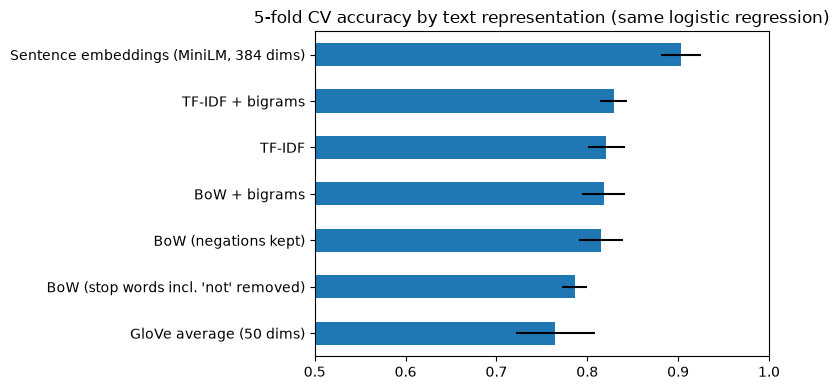

,accuracy,± std
GloVe average (50 dims),0.765,0.043
BoW (stop words incl. 'not' removed),0.786,0.014
BoW (negations kept),0.815,0.024
BoW + bigrams,0.818,0.024
TF-IDF,0.821,0.020
TF-IDF + bigrams,0.829,0.015
"Sentence embeddings (MiniLM, 384 dims)",0.903,0.022


In [29]:
final = pd.DataFrame(results, index=["accuracy", "± std"]).T.sort_values("accuracy")
ax = final["accuracy"].plot(kind="barh", xerr=final["± std"], figsize=(8, 4), xlim=(0.5, 1.0), color="tab:blue")
ax.set_title("5-fold CV accuracy by text representation (same logistic regression)")
plt.tight_layout()
plt.show()
final

On 1,000 short reviews, TF-IDF with clean preprocessing is a strong, cheap baseline, and pretrained sentence embeddings usually come out on top with **no cleaning at all**. On larger, messier text the gap in favour of embeddings tends to grow.

---
## 8. From embeddings to LLMs: how LLMs are trained, in brief

A large language model like GPT, Llama or Claude builds on everything above:

```
text → tokens (sub-words) → embeddings → many transformer layers (attention) → probability of the NEXT token
```

| Stage | What happens | Data | Result |
|---|---|---|---|
| **1. Pretraining** | Predict the next token, billions of times | Trillions of tokens of web text, books, code | A **base model** that knows language and facts but just continues text |
| **2. Instruction tuning** (supervised fine-tuning, SFT) | Learn from example *instruction → good answer* pairs | Tens of thousands to millions of curated examples | Follows instructions, chats |
| **3. Preference alignment** (RLHF / DPO) | Learn which of two answers humans (or a reward model) prefer | Human preference rankings | More helpful, honest, safer answers |

- **BERT** is an **encoder** (reads both directions): good for understanding, embeddings and classification.
- **GPT-style LLMs** are **decoders** (read left to right): good for **generating** text one token at a time.
- **Embedding models** turn text into vectors for search; **LLMs** turn a prompt into new text. **RAG** combines them: find the relevant text with embeddings, then let the LLM answer using it.

➡️ **Notebook 2** covers prompt engineering, guardrails, LLM-as-a-judge, RAG and running an LLM locally.

---
## Summary

| Concept | Key idea |
|---|---|
| Tokenisation | Split text into tokens; LLMs use sub-words |
| Stop words | Remove filler words, but **keep negations** for sentiment |
| Stemming vs lemmatisation | Chop endings vs dictionary base form (needs part of speech) |
| BoW / TF-IDF | Sparse counts; TF-IDF up-weights rare, informative words |
| Word2Vec / GloVe | Dense static embeddings; similar context → similar vector |
| CBOW vs skip-gram | Predict the word from its context vs the context from the word |
| BERT | Contextual embeddings from a transformer encoder |
| Sentence embeddings | One vector per sentence → semantic search, RAG |
| LLMs | Next-token prediction → instruction tuning → preference alignment |

## Try it yourself

1. Add `ngram_range=(1, 3)` to TF-IDF. Does accuracy improve?
2. Try the `glove-wiki-gigaword-100` vectors instead of the 50-dimension ones.
3. Use `fill("The service was [MASK].")` on a few templates. What does BERT expect?
4. Search the reviews for "romantic dinner", "too expensive" and "vegetarian options". Are the results sensible?